# Building a Verifiable Natural-Language Analytics System — a hands-on tutorial

Welcome! This is a **complete, build-along tutorial**. By the end you will understand — and have run —
every part of a system that lets a person ask questions in plain English about a real **data-center IoT
network**, and get answers whose numbers are **guaranteed correct**.

### What you will learn
1. Why LLMs are dangerous for analytics, and the design pattern that fixes it.
2. How to turn raw **network packet captures** into a clean, labelled table.
3. How to build a **truth layer** of exact queries (and why that matters).
4. How to **detect attacks** with two complementary detectors and **evaluate them honestly** on real labels.
5. How to build a **natural-language interface** with trust labels and an LLM **faithfulness gate**.
6. How it is wrapped into a CLI and a web app — and how you would reuse the pattern on your own data.

### Prerequisites
Basic Python and pandas. No security or ML background needed — concepts are explained as we go.

### How to run
`bash tools/get_dad_dataset.sh` to fetch the data, then **Kernel → Restart & Run All**.

---
## Table of contents
0. [Background: the problem and the idea](#bg)
1. [Setup and first look](#setup)
2. [From packets to a labelled table](#parse)
3. [Exploring the sensors and temperature](#explore)
4. [The truth layer: exact queries](#truth)
5. [Detecting the attacks](#detect)
6. [Evaluating honestly (metrics explained)](#eval)
7. [The natural-language interface + faithfulness gate](#interface)
8. [The apps (CLI + web)](#apps)
9. [Try it yourself (exercises)](#exercises)
10. [Summary and further reading](#summary)


<a id="bg"></a>
## 0. Background: the problem and the idea

### The problem — LLMs hallucinate numbers
A Large Language Model predicts text. Ask one *"how many attacks happened on Wednesday?"* and it will
produce a fluent, confident sentence — but the number in it may be **made up**. In analytics, a
confidently wrong number is worse than no answer: people act on it.

### The idea — separate *computing* from *explaining*
> **Deterministic code computes every number (a "truth layer"). The LLM does *only* the wording. An
> automatic "faithfulness" check then verifies the wording did not change any number.**

We call this **Verifiable NL Analytics**. The LLM becomes a *re-phraser*, never a *calculator* — so even
a tiny local model is safe to use.

```
 raw packets (.pcap) + labels
        │  parse + join            (Part 2)
        ▼
   MESSAGES table  ───────────────►  truth layer: exact queries   (Part 4)
        │                                   │
        │  window + score                   │  route question → exact answer
        ▼                                   ▼
   two detectors → fusion  (Part 5-6)   NL interface + trust labels   (Part 7)
        │                                   │
        ▼                                   ▼
   honest evaluation on REAL labels     optional LLM wording + faithfulness gate
```

### The dataset — DAD (a real, labelled IoT-network capture)
**DAD** (Vigoya et al., 2020) is seven days of traffic from a data-center cooling system. Sixteen
temperature sensors publish readings every five minutes over **MQTT** (a lightweight IoT messaging
protocol) to a central broker; everything is captured as **network packets**. An attacker manipulates
the messages in three ways:
- **Modification** — change the temperature value inside a message.
- **Duplication** — replay messages (send more than scheduled).
- **Interception** — drop messages (send fewer).

Crucially, DAD ships **real human labels** for every attack packet — so, unlike synthetic benchmarks, we
can measure detection *honestly*.


<a id="setup"></a>
## 1. Setup and first look
We put the project on the import path and load its modules. All the real logic lives in `src/`; this
notebook simply calls the same functions the app uses.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import preprocess, features, channels, fusion, experiment, interface, llm
from src import query_engine as qe
plt.rcParams["figure.figsize"] = (9, 3.2); plt.rcParams["axes.grid"] = True
print("Ready. Modules imported.")

Ready. Modules imported.


Load all seven days into one datetime-indexed **MESSAGES** frame — the single table everything else reads.

In [2]:
df = preprocess.load_week()
print("shape:", df.shape)
df.head()

shape: (101583, 10)


,frame,src_ip,src_port,topic,temperature,clientid,msgid,label,day,attack_type
ts,,,,,,,,,,
2019-10-20 22:00:02.449276924,1,10.6.56.36,47590.0,NaN,NaN,NaN,NaN,0,mon,none
2019-10-20 22:00:02.449343920,2,10.6.56.1,1883.0,NaN,NaN,NaN,NaN,0,mon,none
2019-10-20 22:00:02.449383974,3,10.6.56.36,47588.0,NaN,NaN,NaN,NaN,0,mon,none
2019-10-20 22:00:02.449403048,4,10.6.56.1,1883.0,NaN,NaN,NaN,NaN,0,mon,none
2019-10-20 22:00:02.449471951,5,10.6.56.36,47592.0,NaN,NaN,NaN,NaN,0,mon,none


**The MESSAGES frame — data dictionary**

| column | meaning |
|---|---|
| `ts` (index) | packet timestamp (UTC) |
| `frame` | packet number in the capture (the join key to the labels) |
| `src_ip` | source IP (`10.6.56.41` = attacker) |
| `src_port` | TCP source port |
| `topic` | MQTT topic (all sensors publish to `IoT`) |
| `temperature` | value parsed from the MQTT payload (`NaN` if the packet is not a PUBLISH) |
| `clientid` | MQTT client = sensor id (e.g. `131` = InRow-13 probe 1) |
| `msgid` | MQTT message id |
| `label` | **ground truth**: 0 normal / 1 attack |
| `attack_type` | modification / duplication / mixed / none |


<a id="parse"></a>
## 2. From packets to a labelled table

### What is happening under the hood?
- A **`.pcap`** file is a recording of raw network packets.
- **MQTT** messages of interest are *PUBLISH* packets: they carry a **topic** and a **payload**. Here the
  payload is just the temperature as text, e.g. `b"15.54"`.
- The dataset's label file lists, for every packet, whether it is an attack. Its `frame.number` equals
  the packet's position in the capture, so we can join labels to packets **exactly** — no fuzzy matching.

Let's parse a single day and look at a few PUBLISH packets:

In [3]:
one = preprocess.parse_pcap(preprocess.DATA_DIR / "capture_1910210000_mon.pcap")
print("packets in Monday's capture:", len(one))
one[one.temperature.notna()].head(4)[["frame", "src_ip", "topic", "temperature"]]

packets in Monday's capture: 14431


,frame,src_ip,topic,temperature
60,61,10.6.56.36,IoT,15.54
61,62,10.6.56.36,IoT,11.81
66,67,10.6.56.36,IoT,20.11
70,71,10.6.56.36,IoT,27.41


The full week joins the labels on `frame.number`. Let's confirm the labels look right and match the paper's published schedule.

attacks total: 544   (paper: 544)
attacks per day: {'mon': 0, 'tue': 0, 'wed': 104, 'thu': 56, 'fri': 192, 'sat': 192, 'sun': 0}


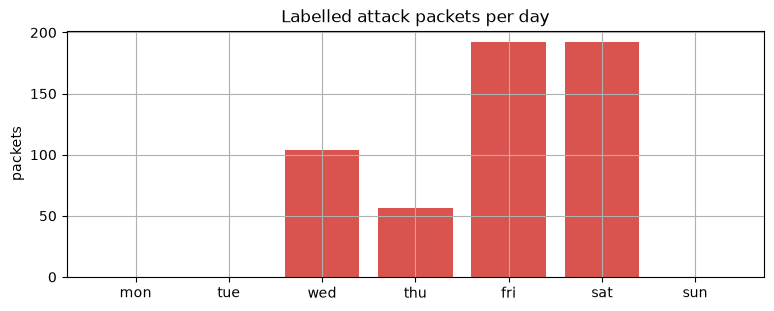

In [4]:
print("attacks total:", int(df.label.sum()), "  (paper: 544)")
per_day = qe.attacks_by_day(df)
print("attacks per day:", per_day)
plt.bar(per_day.keys(), per_day.values(), color="#d9534f")
plt.title("Labelled attack packets per day"); plt.ylabel("packets"); plt.show()

**Takeaway:** most of the work in any real system is getting the data into a *tidy, labelled* table. We even lock it down with a test that the parsed total equals **544** — a regression here would be caught automatically.

<a id="explore"></a>
## 3. Exploring the sensors and temperature

Sixteen sensors: four **InRow** cooling units (13, 15, 23, 25), each with four probes. The client id
encodes unit + probe (`131` = InRow **13**, probe **1**).

16 sensors: [131, 132, 133, 134, 151, 152, 153, 154, 231, 232, 233, 234, 251, 252, 253, 254]


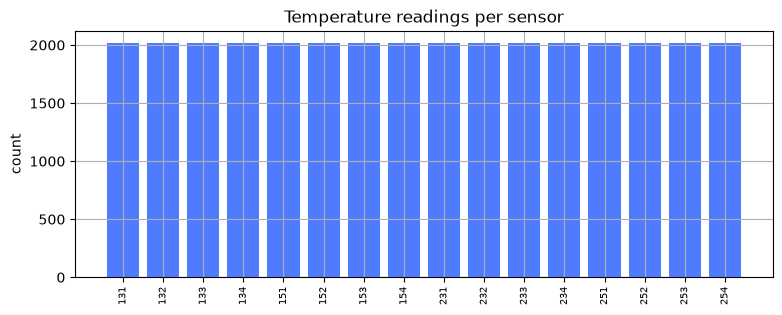

In [5]:
ids = sorted(int(c) for c in df.clientid.dropna().unique())
print(f"{len(ids)} sensors:", ids)
readings = df[df.temperature.notna()].groupby("clientid").size()
plt.bar([str(int(c)) for c in readings.index], readings.values, color="#4f7cff")
plt.title("Temperature readings per sensor"); plt.xticks(rotation=90, fontsize=7); plt.ylabel("count"); plt.show()

{'count': 32288.0, 'mean': 18.43, 'std': 5.76, 'min': 8.67, '25%': 13.22, '50%': 17.45, '75%': 22.62, 'max': 29.4}


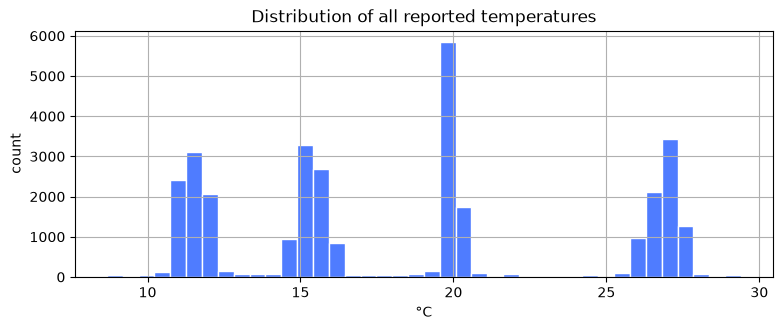

In [6]:
temps = df.temperature.dropna()
print(temps.describe().round(2).to_dict())
plt.hist(temps, bins=40, color="#4f7cff", edgecolor="white")
plt.title("Distribution of all reported temperatures"); plt.xlabel("°C"); plt.ylabel("count"); plt.show()

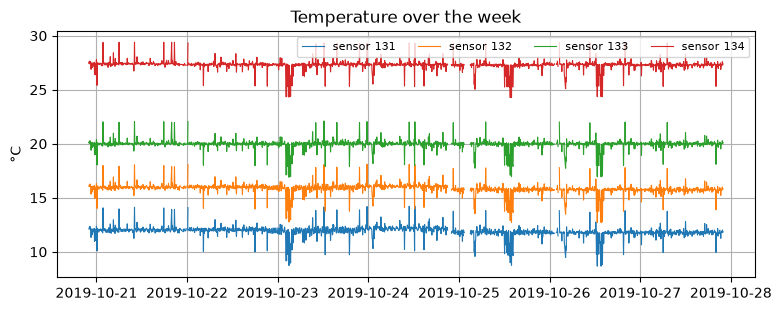

In [7]:
# temperature over the week for a few sensors
sensors = features.sensor_series(df, "5min")
for c in list(sensors.columns)[:4]:
    plt.plot(sensors.index, sensors[c], lw=0.8, label=f"sensor {int(c)}")
plt.legend(ncol=4, fontsize=8); plt.title("Temperature over the week"); plt.ylabel("°C"); plt.show()

The readings have a clear **daily rhythm** (seasonality). The dedicated EDA notebook (`01_data_exploration_and_visualization.ipynb`) decomposes this with STL and shows the autocorrelation and sensor-correlation heatmap — worth a look for the full statistical picture.

<a id="truth"></a>
## 4. The truth layer — code owns the numbers

**The golden rule:** every answer's number is one **exact computation** over the table — never something
a model produced. Here is a query written from scratch; notice it equals plain pandas, so it is
*verifiable*.

In [8]:
def count_attacks(frame, day=None):
    sub = frame if day is None else frame[frame.day == day]
    return int((sub.label == 1).sum())

print("total:", count_attacks(df), "| Wednesday:", count_attacks(df, "wed"))
assert count_attacks(df) == int(df.label.sum()) == 544
print("== pandas ✓  (this is why the answer cannot be hallucinated)")

total: 544 | Wednesday: 104
== pandas ✓  (this is why the answer cannot be hallucinated)


In [9]:
# the project ships a small library of such exact queries in query_engine.py
print("by type   :", qe.attack_breakdown(df))
print("attacker  :", qe.attacker_ips(df))
print("sensors   :", len(qe.sensor_ids(df)))
print("hottest Fri:", round(qe.temperature_stat(df, "max", day="fri"), 2), "°C")

by type   : {'duplication': 56, 'mixed': 384, 'modification': 104}
attacker  : ['10.6.56.41']
sensors   : 16
hottest Fri: 29.28 °C


An independent script, `verify_results.py`, recomputes these a **second way** (e.g. summing the raw label files) and checks 12/12 — so a bug in either the parser or a query cannot pass silently.

<a id="detect"></a>
## 5. Detecting the attacks — two complementary views

The three attacks reveal themselves in **different signals**:

| attack | what changes | where you see it |
|---|---|---|
| modification | the temperature *value* | the **sensor** signal (a residual spike) |
| duplication | more messages, shorter gaps | the **network-flow** features |
| interception | fewer messages, longer gaps | the **network-flow** features |

So we build **two detector channels**. We window everything into 5-minute bins (the publish cadence).

In [10]:
labels = features.window_labels(df, "5min")
flow = features.flow_features(df, "5min").reindex(labels.index).fillna(0.0)
sensors_w = features.sensor_series(df, "5min").reindex(labels.index)

value_s = channels.value_score(sensors_w)   # max |z| of temperature  -> modification
flow_s  = channels.flow_score(flow)          # Isolation Forest        -> duplication/interception
print("value channel:", value_s.shape, "| flow channel:", flow_s.shape)

value channel: (2016,) | flow channel: (2016,)


**How each detector works (in one line):**
- **Value channel** — for each sensor we compute a *z-score* (how many standard deviations from its
  own mean); a modified reading is far from the pattern, so |z| spikes.
- **Flow channel** — an **Isolation Forest**, an unsupervised model that "isolates" unusual points; a
  window with an abnormal message rate or timing gets a high anomaly score.

Let's plot the two channel scores with the true attack windows shaded — you can *see* the complementarity.

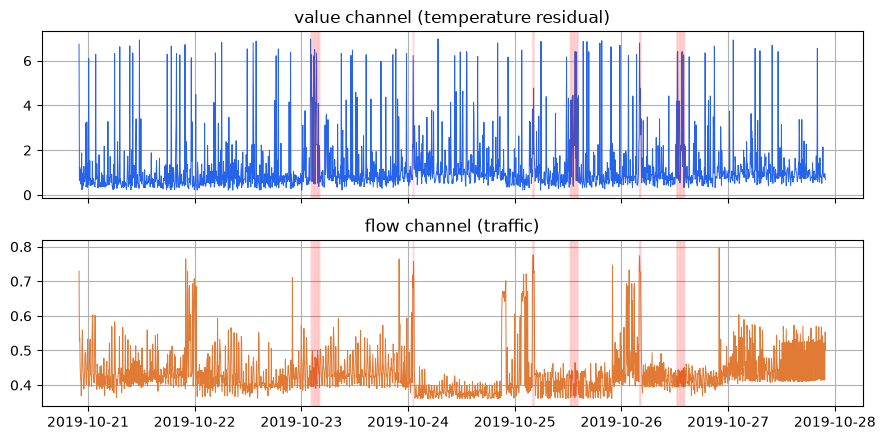

In [11]:
atk = labels[labels.label == 1]
fig, ax = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
ax[0].plot(value_s.index, value_s.values, color="#2563eb", lw=0.7); ax[0].set_title("value channel (temperature residual)")
ax[1].plot(flow_s.index, flow_s.values, color="#e07a34", lw=0.7); ax[1].set_title("flow channel (traffic)")
for a in ax:
    for t in atk.index: a.axvline(t, color="red", alpha=0.04)
plt.tight_layout(); plt.show()

### Fusing the two channels
If each channel catches different attacks, combining them should catch more. Two ways:
- **Late fusion** — rank each channel's scores and take the max (an *OR* of two specialists).
- **Early fusion** — concatenate the features and train one detector on the joint space.

We'll compare both against single channels and a *supervised* combiner next.

<a id="eval"></a>
## 6. Evaluating honestly — and what the metrics mean

Because attacks are **rare** (~4.5% of windows), plain "accuracy" is useless (always-say-normal scores 95%).
We use:
- **Precision** = of the windows we flag, how many are truly attacks.
- **Recall** = of the true attacks, how many we flag.
- **F1** = balance of the two.
- **Average precision (AP)** = area under the precision–recall curve — a single, *threshold-free* score.
- **Point-adjusted** metrics = event-level: if we flag *any* window of an attack episode, the whole
  episode counts as caught (standard for time-series anomalies).
- **95% bootstrap CI** = resample the windows many times to get an uncertainty range on AP.

`experiment.run_experiment` computes all of this for five configurations:

In [12]:
res = experiment.run_experiment(df)
res[["config", "AP", "AP_lo", "AP_hi", "f1", "precision", "recall", "f1_pa", "recall_pa"]].round(3)

,config,AP,AP_lo,AP_hi,f1,precision,recall,f1_pa,recall_pa
0,flow_only,0.136,0.077,0.222,0.226,0.412,0.156,0.294,0.178
1,value_only,0.183,0.136,0.245,0.379,0.331,0.444,0.804,0.889
2,early_fusion,0.147,0.108,0.206,0.289,0.202,0.511,0.732,1.000
3,late_fusion,0.171,0.123,0.246,0.306,0.214,0.533,0.789,1.000
4,supervised,0.101,0.075,0.141,0.212,0.147,0.378,0.554,1.000


In [13]:
res_pt = experiment.run_experiment(df)  # per-type recall makes the complementarity explicit
res_pt[["config", "recall_modification", "recall_duplication", "recall_mixed"]].round(3)

,config,recall_modification,recall_duplication,recall_mixed
0,flow_only,0.000,1.0,0.167
1,value_only,0.462,0.5,0.433
2,early_fusion,0.423,1.0,0.517
3,late_fusion,0.462,1.0,0.533
4,supervised,0.423,1.0,0.317


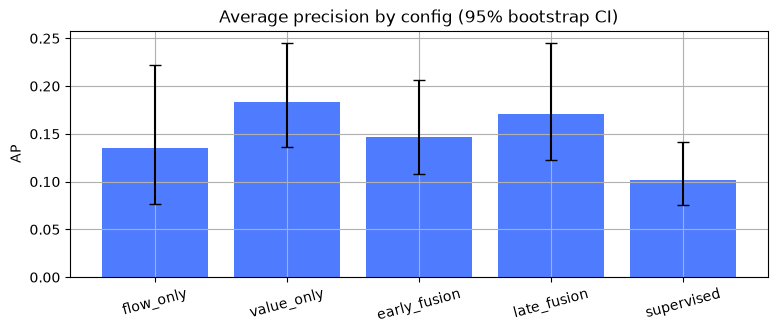

In [14]:
plt.bar(res.config, res.AP, yerr=[res.AP - res.AP_lo, res.AP_hi - res.AP], capsize=4, color="#4f7cff")
plt.title("Average precision by config (95% bootstrap CI)"); plt.ylabel("AP"); plt.xticks(rotation=15); plt.show()

**How to read this (the honest story):**
- **Complementarity is real:** `flow_only` has **0.00** recall on *modification* but **1.00** on
  *duplication*; the value channel is the opposite. Each is blind to the other's attack.
- **Fusion trades precision for recall** and reaches **1.00 point-adjusted recall** (it catches every
  attack *episode*).
- **But the AP confidence intervals overlap**, so *no configuration is significantly best on AP* — a
  point-estimate alone would have misled us.
- **The *supervised* combiner is the worst.** Evaluated with honest **day-blocked** cross-validation (an
  attack episode never appears in both train and test), it overfits — because attack *type* is
  confounded with *day*, the learned weighting doesn't transfer. Lesson: with scarce, clustered labels,
  a simple unsupervised rule can beat a learned model. (See `report/MODELS.md`.)

This is exactly the kind of nuanced, defensible result that *real labels* + *proper metrics* make possible.

<a id="interface"></a>
## 7. The natural-language interface + the faithfulness gate

A **deterministic** parser maps the question to an intent (count, attacker, temperature, sensors,
anomalies, …) and scope, calls the truth layer, and returns a **trust-labelled** answer
(🔢 computed / 📚 context / 🧠 inferred). The number is exact *before* any LLM is involved.

In [15]:
bot = interface.Interface(df)
for q in ["How many attacks on Wednesday?", "Which IP is the attacker?",
          "Show all the sensors in the dataset", "Show me the anomalies"]:
    a = bot.ask(q)
    print("Q:", q, "\n   ->", a.text)
    if a.context: print("      context:", a.context)

Q: How many attacks on Wednesday? 
   -> There were 104 labelled attack packets on Wednesday.
Q: Which IP is the attacker? 
   -> The attack traffic comes from 10.6.56.41.
      context: In DAD all attacks originate from a single injected host.
Q: Show all the sensors in the dataset 
   -> The dataset has 16 sensors (MQTT client ids): [131, 132, 133, 134, 151, 152, 153, 154, 231, 232, 233, 234, 251, 252, 253, 254].
      context: Client ids encode the cooling unit and probe — e.g. 131 = InRow 13, probe 1 (4 InRow units × 4 probes: supply-air, return-air, entering-fluid, leaving-fluid).
Q: Show me the anomalies 
   -> There are 544 labelled anomalies (network attacks) across 4 days: Wednesday, Thursday, Friday, Saturday.
      context: By type — duplication 56, mixed 384, modification 104.


The LLM only *rewords*. A **faithfulness gate** compares the numbers in the facts vs the wording and rejects any invented figure:

In [16]:
facts = "There were 104 labelled attack packets on Wednesday."
print("good  :", llm.faithfulness(facts, "On Wednesday, 104 attack packets were flagged."))
print("bad   :", llm.faithfulness(facts, "There were about 900 attacks."))   # 900 is 'invented'

good  : {'ok': True, 'dropped': [], 'invented': []}
bad   : {'ok': False, 'dropped': [104.0], 'invented': [900.0]}


In [17]:
# with a local Ollama model, the interface rewords automatically; the gate keeps the numbers exact
if llm.is_available():
    a = interface.Interface(df, use_llm=True).ask("How many attacks on Wednesday?")
    print("AI reworded:", a.text, "| used_llm =", a.used_llm)
else:
    print("No local model running -> the exact template is shown (still correct).")

AI reworded: On Wednesday, there were 104 labelled attack packets. | used_llm = True


**Why this is safe:** the guarantee is *structural*, not a matter of trusting the model. Numbers are exact upstream (truth layer) and re-checked downstream (gate). A cheap 3B model can only ever be a re-phraser.

<a id="apps"></a>
## 8. The apps
Two thin wrappers reuse everything above — neither contains analytics logic; both just call
`interface.Interface(df).ask(...)`:
- **CLI:** `python3.12 apps/chat.py "show me the anomalies"` (add `--llm` to reword).
- **Web:** `python3.12 apps/web/app.py` → a browser chat. Type a question or click an example, see the
  trust-labelled answer **and a chart** (bar of attacks/day, line of temperature/traffic), and flip
  **Explain with AI** on when a local model is up.


<a id="exercises"></a>
## 9. Try it yourself

**Exercise 1 — ask your own questions.** Edit the list and run.

In [18]:
for q in ["How many duplication attacks were there?",
          "What was the lowest temperature on Saturday?",
          "How many messages per hour on Monday?"]:
    print(q, "->", interface.Interface(df).ask(q).text)

How many duplication attacks were there? -> There were 56 labelled attack packets (duplication).
What was the lowest temperature on Saturday? -> The lowest reported temperature on Saturday was 8.67 °C.
How many messages per hour on Monday? -> There were 14,431 MQTT/network messages on Monday.


**Exercise 2 — add a new query to the truth layer.** Write an exact function and check it against
pandas (the pattern every query follows).

In [19]:
def attacks_between(frame, start_hour, end_hour):
    """Count attack packets whose UTC hour is in [start_hour, end_hour)."""
    h = frame.index.hour
    return int(((frame.label == 1) & (h >= start_hour) & (h < end_hour)).sum())

print("attacks 00:00-06:00 UTC:", attacks_between(df, 0, 6))
# sanity check it against a direct pandas expression
assert attacks_between(df, 0, 6) == int(df[(df.index.hour < 6)].label.sum())
print("matches pandas ✓ — you just extended the truth layer safely")

attacks 00:00-06:00 UTC: 352
matches pandas ✓ — you just extended the truth layer safely


**Exercise 3 (open-ended).** Add a `sensors`-style intent to `interface_parsing.py` + a branch in `interface._route`, then a test in `tests/`. Run `bash reproduce.sh` — everything should stay green.

<a id="summary"></a>
## 10. Summary and further reading

**What we built:** a system where **code computes every number, the LLM only explains, and a gate
verifies** — applied to a real data-center IoT network with genuine attack labels.

**The reusable recipe for *your* data:**
1. Load & label your data into one tidy table.
2. Write a handful of **exact queries** for the questions you care about (and check them `== pandas`).
3. Add **detectors** if you need anomaly finding, and evaluate on real labels with proper metrics.
4. Put a **deterministic intent router** in front, returning trust-labelled answers.
5. Add an **LLM + faithfulness gate** for nicer wording — optional and safe by construction.

**Further reading in this repo:** `report/REPORT.md` (the write-up), `report/MODELS.md` (the detector
comparison), `report/EVALUATION.md` (the running results log), `docs/ARCHITECTURE.md` (module map),
`notebooks/01_data_exploration_and_visualization.ipynb` (full EDA).

**Dataset:** Vigoya, L., Fernández, D., Carneiro, V. and Cacheda, F. (2020) *Annotated Dataset for
Anomaly Detection in a Data Center with IoT Sensors*, Sensors 20(13), 3745.
